In [39]:
library( tidyverse )
library( ggplot2 )
simulate_two_dice <- function(
	number_of_times,
	probabilities = rep( 1/6, 6 )
) {
	die1 = sample( 1:6, size = number_of_times, replace = T, prob = probabilities )
	die2 = sample( 1:6, size = number_of_times, replace = T, prob = probabilities )
	return( die1 + die2 )
}

options(repr.plot.width = 6, repr.plot.height = 4)



In [47]:
mytheme = function( fontsize = 16 ) {
	(
		theme_minimal( fontsize )
		+ theme(
			axis.title.y = element_text( angle = 0, hjust = 1, vjust = 0.5 )
		)
	)
}

x_scale = ggplot2::scale_x_continuous( breaks = 2:12 )

In [48]:
#data = readr::read_tsv( "https://www.chg.ox.ac.uk/bioinformatics/training/msc_gm/2026/data/dice_data1.tsv" )
data = readr::read_tsv( "dice_data1.tsv" )
print( data )


Rows: 30 Columns: 2
── Column specification ─────────────────────────────────────────────────────────────────────────────────────────────────
Delimiter: "\t"
dbl (2): roll, sum_of_dice

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


# A tibble: 30 × 2
    roll sum_of_dice
   <dbl>       <dbl>
 1     1           8
 2     2           6
 3     3           8
 4     4           5
 5     5           8
 6     6          11
 7     7          11
 8     8          11
 9     9           6
10    10           8
# ℹ 20 more rows


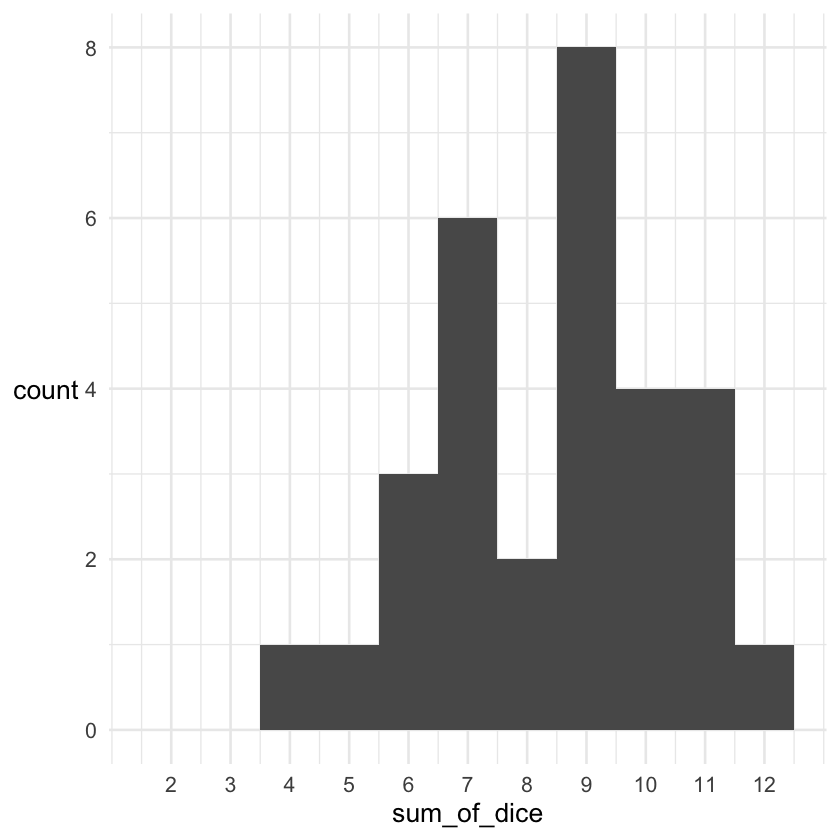

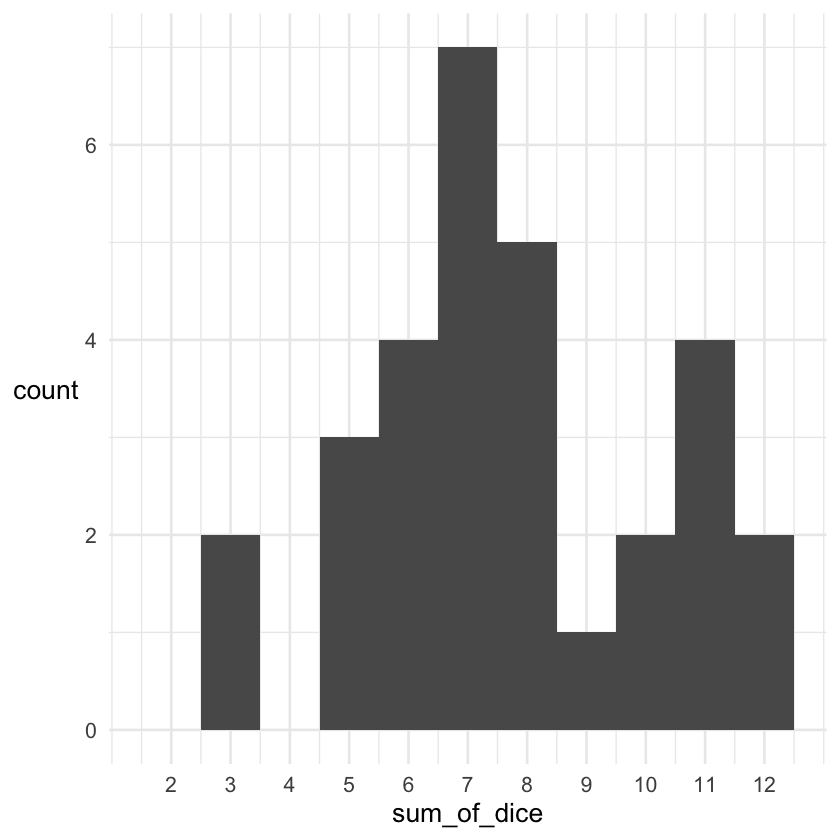

In [17]:
simulation = tibble::tibble(
	roll = 1:30,
	sum_of_dice = simulate_two_dice( 30, probabilities = c( 0, 0.2, 0.2, 0.2, 0.2, 0.2 ))
)
breaks = (2:13) - 0.5
ggplot( data = simulation ) + geom_histogram( aes( x= sum_of_dice), breaks = breaks ) + mytheme() + scale_x_continuous( breaks = 2:12 )
ggplot( data = data       ) + geom_histogram( aes( x= sum_of_dice), breaks = breaks ) + mytheme() + scale_x_continuous( breaks = 2:12 )


In [25]:
likelihood <- function( observed, probabilities = rep( 1/6, 6 ) ) {
	dice1 = tibble::tibble( dice1 = 1:6, dice1_probability = probabilities )
	dice2 = tibble::tibble( dice2 = 1:6, dice2_probability = probabilities )
	both_dice = (
		dice1
		%>% cross_join( dice2 )
		%>% mutate(
			sum_of_dice = dice1 + dice2,
			probability = dice1_probability * dice2_probability
		)
	)
	probabilities = (
		both_dice
		%>% group_by( sum_of_dice )
		%>% summarise(
			number_of_ways = n(),
			probability = sum( probability )
		)
	)

	result = (
		tibble::tibble( sum_of_dice = observed )
		%>% left_join( probabilities, by = "sum_of_dice" )
	)

	return( result )
}


In [19]:
likelihood( data$sum_of_dice, rep( 1/6, 6 ))

sum_of_dice,number_of_ways,probability
<dbl>,<int>,<dbl>
8,5,0.13888889
6,5,0.13888889
8,5,0.13888889
5,4,0.11111111
8,5,0.13888889
11,2,0.05555556
11,2,0.05555556
11,2,0.05555556
6,5,0.13888889


In [20]:
total_likelihood = function( observed, probabilities = rep( 1/6, 6 ) ) {
	prod( likelihood( observed, probabilities )$sum_of_dice )
}

total_likelihood( data$sum_of_dice )

[1] 7.465682e+25

In [34]:
total_loglikelihood = function( observed, probabilities = rep( 1/6, 6 ) ) {
	sum(
		log(
			likelihood( observed, probabilities )$probability
		)
	)
}

likelihood( 2, rep( 1/6, 6 ))
total_loglikelihood( 1:6, rep( 1/6, 6 ) )

loglikelihoods = tibble::tribble(
	~model, ~loglikelihood,
	"Normal dice",        total_loglikelihood( data$sum_of_dice, rep( 1/6, 6 ) ),
	"Omit 1",             total_loglikelihood( data$sum_of_dice, c(  0.0,  0.2,  0.2,  0.2,  0.2,  0.2 ) ),
	"Omit 2",             total_loglikelihood( data$sum_of_dice, c(  0.2,  0.0,  0.2,  0.2,  0.2,  0.2 ) ),
	"Omit 3",             total_loglikelihood( data$sum_of_dice, c(  0.2,  0.2,  0.0,  0.2,  0.2,  0.2 ) ),
	"Omit 4",             total_loglikelihood( data$sum_of_dice, c(  0.2,  0.2,  0.2,  0.0,  0.2,  0.2 ) ),
	"Omit 5",             total_loglikelihood( data$sum_of_dice, c(  0.2,  0.2,  0.2,  0.2,  0.0,  0.2 ) ),
	"Omit 6",             total_loglikelihood( data$sum_of_dice, c(  0.2,  0.2,  0.2,  0.2,  0.2,  0.0 ) )
)

print( loglikelihoods )

sum_of_dice,number_of_ways,probability
<dbl>,<int>,<dbl>
2,1,0.02777778


[1] NA

# A tibble: 7 × 2
  model       loglikelihood
  <chr>               <dbl>
1 Normal dice         -68.6
2 Omit 1             -Inf  
3 Omit 2             -Inf  
4 Omit 3              -66.7
5 Omit 4              -68.6
6 Omit 5             -Inf  
7 Omit 6             -Inf  


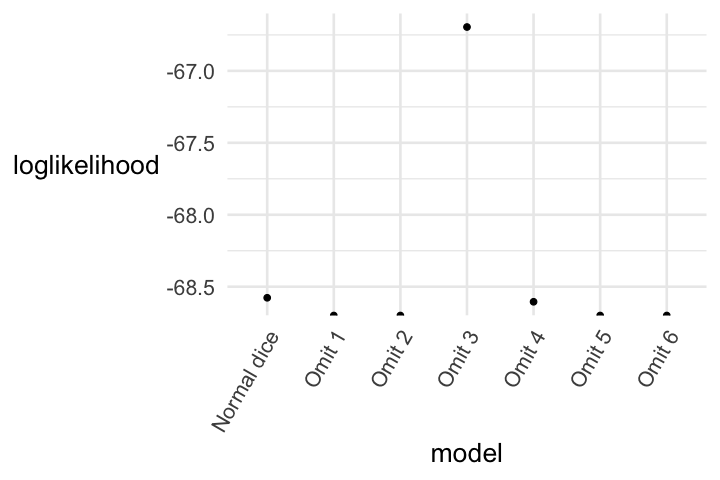

In [40]:
(
	ggplot( data = loglikelihoods )
	+ geom_point(
		aes( x = model, y = loglikelihood )
	)
    + mytheme()
    + theme(
        axis.text.x = element_text( angle = 60, hjust = 1, vjust = 1 )
    )
)


# A tibble: 7 × 4
  model       loglikelihood likelihood posterior
  <chr>               <dbl>      <dbl>     <dbl>
1 Normal dice         -68.6   1.65e-30     0.117
2 Omit 1             -Inf     0            0    
3 Omit 2             -Inf     0            0    
4 Omit 3              -66.7   1.08e-29     0.769
5 Omit 4              -68.6   1.60e-30     0.114
6 Omit 5             -Inf     0            0    
7 Omit 6             -Inf     0            0    


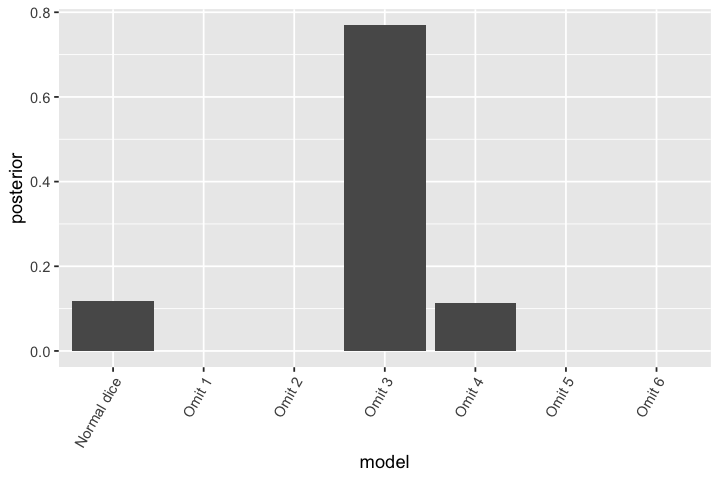

In [42]:
posteriors = (
	loglikelihoods
	%>% mutate(
		likelihood = exp( loglikelihood ),
		posterior  = likelihood / sum( likelihood )
	)
)

print( posteriors )

(
	ggplot( data = posteriors )
	+ geom_col( aes( x = model, y = posterior ))
	    + theme(
        axis.text.x = element_text( angle = 60, hjust = 1, vjust = 1 )
    )
)


In [49]:
data2 = readr::read_tsv( "dice_data2.tsv" )
data3 = readr::read_tsv( "dice_data3.tsv" )
combined_data = bind_rows( data, data2, data3 )


Rows: 30 Columns: 2
── Column specification ─────────────────────────────────────────────────────────────────────────────────────────────────
Delimiter: "\t"
dbl (2): roll, sum_of_dice

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 251 Columns: 2
── Column specification ─────────────────────────────────────────────────────────────────────────────────────────────────
Delimiter: "\t"
dbl (2): roll, sum_of_dice

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


# A tibble: 11 × 3
   sum_of_dice number_of_ways probability
         <int>          <int>       <dbl>
 1           2              1        0.04
 2           3              2        0.08
 3           4              3        0.04
 4           5              4        0.08
 5           6              5        0.16
 6           7              6        0.16
 7           8              5        0.12
 8           9              4        0.08
 9          10              3        0.12
10          11              2        0.08
11          12              1        0.04
# A tibble: 11 × 3
   sum_of_dice     n frequency
         <dbl> <int>     <dbl>
 1           2    20    0.0643
 2           3    27    0.0868
 3           4    12    0.0386
 4           5    13    0.0418
 5           6    45    0.145 
 6           7    65    0.209 
 7           8    34    0.109 
 8           9    13    0.0418
 9          10    28    0.0900
10          11    37    0.119 
11          12    17    0.0547


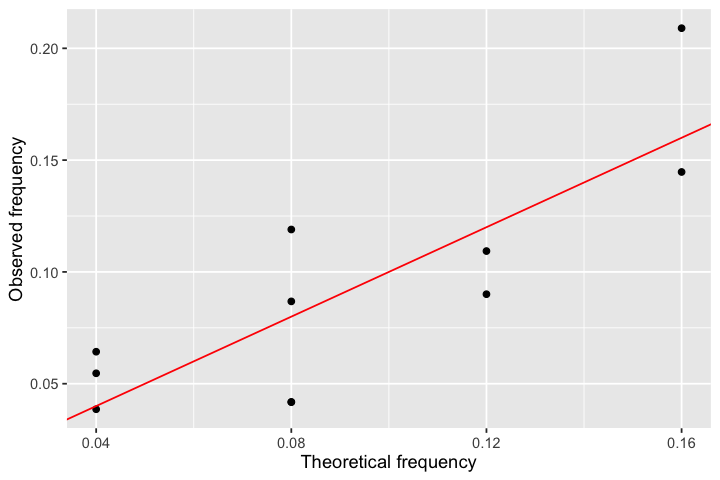

In [58]:
combined_data = bind_rows( data, data2, data3 )
number_of_observations = nrow( combined_data )
observed_frequencies = (
    combined_data
	%>% group_by( sum_of_dice )
	%>% summarise(
		n = n(),
		frequency = n / number_of_observations
	)
)

theoretical_frequencies = likelihood(
	2:12,
	probabilities = c( 0.2, 0.2, 0, 0.2, 0.2, 0.2 )
)

print( theoretical_frequencies )
print( observed_frequencies )

joined = (
	theoretical_frequencies
	%>% inner_join( observed_frequencies, by = "sum_of_dice" )
)

(
	ggplot( data = joined )
	+ geom_point( aes( x = probability, y = frequency ))
	+ geom_abline( slope = 1, col = 'red' )
	+ xlab( "Theoretical frequency" )
	+ ylab( "Observed frequency" )
)



In [64]:
simulation = simulate_two_dice( nrow( data ), c( 0.2, 0.2, 0, 0.2, 0.2, 0.2 ))
print( simulation )


 [1]  6  6  6  6  5  7 12  3  7 10  5  7  5  5  7 10 10  6  8  5  9  7  4  4  7
[26]  9  8  3  6  7


ERROR: Error in simulation$sum_of_dice: $ operator is invalid for atomic vectors


In [73]:
outcomes = tibble::tibble( sum_of_dice = 2:12 )
print(
    outcomes
    %>% left_join(
        tibble::tibble( sum_of_dice = simulation ),
        by = "sum_of_dice"
    )
)


# A tibble: 32 × 1
   sum_of_dice
         <int>
 1           2
 2           3
 3           3
 4           4
 5           4
 6           5
 7           5
 8           5
 9           5
10           5
# ℹ 22 more rows


In [98]:


find_best_fit_frequencies <- function( observed ) {
	outcomes = tibble::tibble( sum_of_dice = 2:12 )
	data_counts = sapply( 2:12, function(i) { sum( observed == i ) })
	return(
		tibble::tibble(
			sum_of_dice = 2:12,
			count = data_counts
        ) %>% mutate(
			frequency = count / length(observed)
		)
	)
}

find_best_fit_loglikelihood <- function( data ) {
	frequencies = find_best_fit_frequencies( data )
    return(
		sum(
			frequencies$count * log( frequencies$frequency ),
            na.rm = T
		)
	)
}

find_best_fit_frequencies( simulation )
find_best_fit_loglikelihood( simulation )
table( simulation ) / nrow(data)




sum_of_dice,count,frequency
<int>,<int>,<dbl>
2,0,0.00000000
3,5,0.16666667
4,2,0.06666667
5,0,0.00000000
6,7,0.23333333
7,2,0.06666667
8,1,0.03333333
9,3,0.10000000
10,5,0.16666667


[1] -60.70657

simulation
         3          4          6          7          8          9         10 
0.16666667 0.06666667 0.23333333 0.06666667 0.03333333 0.10000000 0.16666667 
        11         12 
0.13333333 0.03333333 

`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.


[1] 0


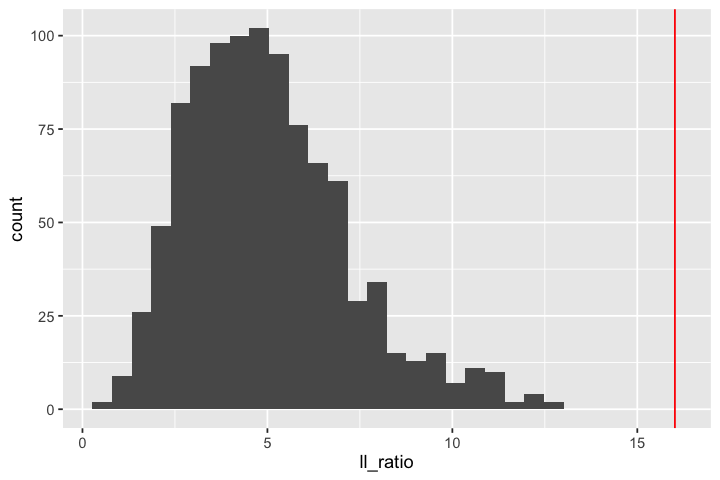

In [106]:
#data = combined_data
number_of_simulations = 1000

result = tibble::tibble(
	simulation        = 1:number_of_simulations,
	maximum_ll        = NA,
    model_ll          = NA
)

mymodel = c( 0.2, 0.2, 0, 0.2, 0.2, 0.2 )
for( i in 1:nrow( result )) {
	simulation = simulate_two_dice( nrow( data ), mymodel )
    
	result$maximum_ll[i] = find_best_fit_loglikelihood( simulation )
	result$model_ll[i]   = total_loglikelihood( simulation, mymodel )
}

result$ll_ratio = result$maximum_ll - result$model_ll

actual_ll_ratio = find_best_fit_loglikelihood( data$sum_of_dice ) - total_loglikelihood( data$sum_of_dice, mymodel )

(
	ggplot( data = result )
	+ geom_histogram( aes( x = ll_ratio ))
    + geom_vline( xintercept = actual_ll_ratio, col = 'red' )
)

# P-value calculation
# How likely were we to see such an extreme result?

p_value = length( which( result$ll_ratio >= actual_ll_ratio )) / number_of_simulations
print( p_value )